In [2]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2


In [3]:
import pandas as pd

In [4]:
df = pd.read_csv('pet_adoption_data.csv')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2007 entries, 0 to 2006
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   PetID               2007 non-null   int64  
 1   PetType             2007 non-null   object 
 2   Breed               2007 non-null   object 
 3   AgeMonths           2007 non-null   int64  
 4   Color               2007 non-null   object 
 5   Size                2007 non-null   object 
 6   WeightKg            2007 non-null   float64
 7   Vaccinated          2007 non-null   int64  
 8   HealthCondition     2007 non-null   int64  
 9   TimeInShelterDays   2007 non-null   int64  
 10  AdoptionFee         2007 non-null   int64  
 11  PreviousOwner       2007 non-null   int64  
 12  AdoptionLikelihood  2007 non-null   int64  
dtypes: float64(1), int64(8), object(4)
memory usage: 204.0+ KB


In [6]:
y = df["AdoptionLikelihood"]

In [7]:
print(y)

0       0
1       0
2       0
3       0
4       0
       ..
2002    1
2003    0
2004    0
2005    0
2006    0
Name: AdoptionLikelihood, Length: 2007, dtype: int64


<h3>Chi-square test for Categorical data</h3>

In [8]:
X = df[["Color", "Breed", "PetType", "Size"]]

In [9]:
X['Color'].value_counts()

Color
White     420
Orange    409
Gray      400
Black     395
Brown     383
Name: count, dtype: int64

In [11]:
X_encoded = pd.get_dummies(X) # One-hot Encoding

In [12]:
X_encoded.head(5)

,Color_Black,Color_Brown,Color_Gray,Color_Orange,Color_White,Breed_Golden Retriever,Breed_Labrador,Breed_Parakeet,Breed_Persian,Breed_Poodle,Breed_Rabbit,Breed_Siamese,PetType_Bird,PetType_Cat,PetType_Dog,PetType_Rabbit,Size_Large,Size_Medium,Size_Small
0,False,False,False,True,False,False,False,True,False,False,False,False,True,False,False,False,True,False,False
1,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,True,True,False,False
2,False,False,False,True,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False
3,False,False,False,False,True,False,False,True,False,False,False,False,True,False,False,False,False,False,True
4,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,True,True,False,False


In [14]:
selector = SelectKBest(score_func=chi2, k="all")

X_chi = selector.fit_transform(X_encoded, y)

In [15]:
chi_scores = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Chi2_Score": selector.scores_,
    "P_Value": selector.pvalues_
})

chi_scores = chi_scores.sort_values(
    "Chi2_Score",
    ascending=False
)

print(chi_scores)

                   Feature  Chi2_Score       P_Value
17             Size_Medium  281.554749  3.441855e-63
6           Breed_Labrador  134.378818  4.514517e-31
16              Size_Large   86.869211  1.159403e-20
18              Size_Small   69.348201  8.252788e-17
14             PetType_Dog   43.298153  4.700270e-11
10            Breed_Rabbit   12.507832  4.052495e-04
15          PetType_Rabbit   12.507832  4.052495e-04
8            Breed_Persian    4.460369  3.468999e-02
13             PetType_Cat    3.891080  4.854319e-02
4              Color_White    3.462036  6.279296e-02
7           Breed_Parakeet    1.551063  2.129786e-01
12            PetType_Bird    1.551063  2.129786e-01
5   Breed_Golden Retriever    1.073451  3.001673e-01
3             Color_Orange    0.658095  4.172331e-01
11           Breed_Siamese    0.461195  4.970658e-01
2               Color_Gray    0.363116  5.467810e-01
0              Color_Black    0.322635  5.700287e-01
9             Breed_Poodle    0.036878  8.4771

In [17]:
# Create contingency table
from scipy.stats import chi2_contingency
contingency_table = pd.crosstab(
    df["Color"],
    df["AdoptionLikelihood"]
)

print(contingency_table)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)
print("Degrees of freedom:", dof)

# Decision
if p_value < 0.05:
    print("Reject H0: Color is significantly associated with AdoptionLikelihood.")
else:
    print("Fail to reject H0: No significant association between Color and AdoptionLikelihood.")

AdoptionLikelihood    0    1
Color                       
Black               260  135
Brown               258  125
Gray                263  137
Orange              267  142
White               300  120
Chi-square statistic: 4.812689904113482
p-value: 0.30706215359395966
Degrees of freedom: 4
Fail to reject H0: No significant association between Color and AdoptionLikelihood.


In [21]:
from scipy.stats import f_oneway

groups = [
    group["AgeMonths"].values
    for name, group in df.groupby("AdoptionLikelihood")
]
print(len(groups))
f_stat, p_value = f_oneway(*groups)

print("F-statistic:", f_stat)
print("p-value:", p_value)

if p_value < 0.05:
    print("Reject H0: AgeMonths differs across AdoptionLikelihood groups.")
else:
    print("Fail to reject H0: No significant difference in AgeMonths.")

2
F-statistic: 85.47637837856891
p-value: 5.806012058413437e-20
Reject H0: AgeMonths differs across AdoptionLikelihood groups.


<h3>Image dataset</h3>

In [41]:
#Example of supress warnings for Numpy version out of range (optional)
import warnings
warnings.filterwarnings("ignore", category=Warning)

#Pull in the libraries we need
import numpy as np
import pandas as pd
from pandas import DataFrame
from sklearn.datasets import load_digits

#New libraries for access to transformation and preprocessing tasks
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from collections import Counter

#Pull in the plotting library and specify to display inline/static images
import matplotlib.pyplot as plt

In [42]:
#First step is to load the data into an oject
digitsRaw = load_digits()

In [24]:
#Using the shape command, you can investigate the dimensionality
print('Shape of Data (X):',digitsRaw.data.shape)
print('Shape of Target Data (y)', digitsRaw.target.shape)

#We have 1797 data samples, observations, or images each 8x8 in size
print('Shape of each of images', digitsRaw.images.shape)

Shape of Data (X): (1797, 64)
Shape of Target Data (y) (1797,)
Shape of each of images (1797, 8, 8)


In [28]:
X = digitsRaw.data
Y = digitsRaw.target

In [29]:
print(X[0])

[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]


In [30]:
print(Y[0])

0


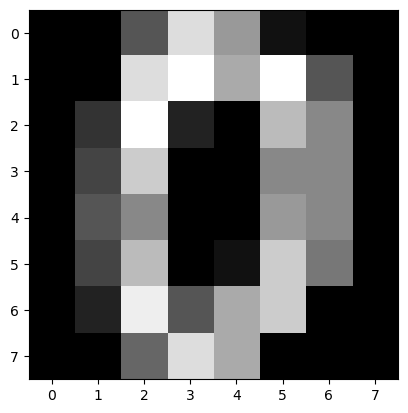

In [33]:
plt.imshow(digitsRaw.images[0], cmap='gray')

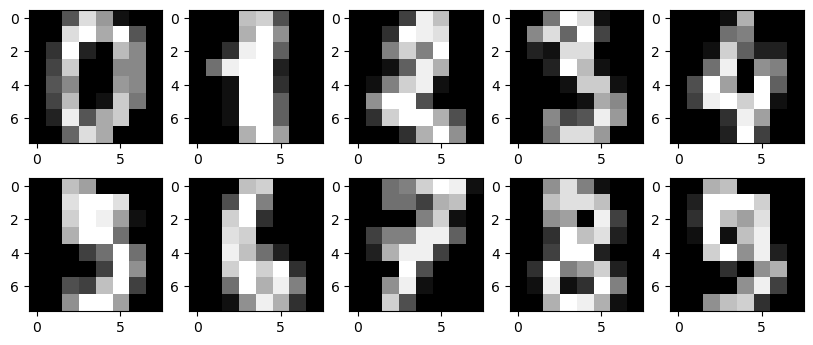

In [27]:
#Setup a figure to display the first 10 images, in 5 columns and 2 rows
plt.figure(figsize=(5*2, 2*2))

#Loop through and plot all of them using the imshow command
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(digitsRaw.images[i,:,:], cmap='gray')

In [34]:
#Step1: Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [35]:
#PCA reduce to 2 for visualization purposes
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)


In [37]:
print(X.shape)
print(X_scaled.shape)
print(X_pca.shape)

(1797, 64)
(1797, 64)
(1797, 2)


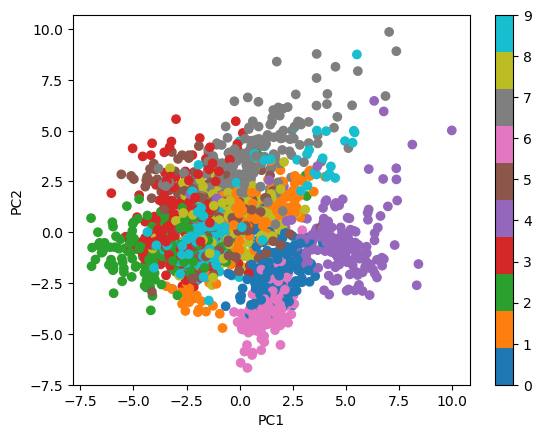

In [38]:
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=Y, cmap='tab10')
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar()
plt.show()

## Balanced vs. Imbalanced Data

In [40]:
#Check the classes/target vector to see if our data is balanced
print('Original Counts:', dict(sorted(Counter(digitsRaw.target).items())))

Original Counts: {0: 178, 1: 182, 2: 177, 3: 183, 4: 181, 5: 182, 6: 181, 7: 179, 8: 174, 9: 180}


In [41]:
#Over Sampling
#Make digit 0 the majority class
class_0_idx = np.where(Y == 0)[0]
other_idx = np.where(Y != 0)[0]

In [42]:
# Duplicate digit 0 several times
X_0 = X[class_0_idx]
Y_0 = Y[class_0_idx]

X_imbalanced = np.vstack([
    X_0,
    X_0,
    X_0,       # duplicate class 0
    X[other_idx]
])

Y_imbalanced = np.concatenate([
    Y_0,
    Y_0,
    Y_0,       # duplicate class 0
    Y[other_idx]
])

print("Imbalanced Counts:",
      dict(sorted(Counter(Y_imbalanced).items())))

Imbalanced Counts: {0: 534, 1: 182, 2: 177, 3: 183, 4: 181, 5: 182, 6: 181, 7: 179, 8: 174, 9: 180}


In [43]:
# Oversampling
from sklearn.utils import resample

X_over = []
Y_over = []

max_count = max(Counter(Y_imbalanced).values())

for class_label in np.unique(Y_imbalanced):

    X_class = X_imbalanced[Y_imbalanced == class_label]
    Y_class = Y_imbalanced[Y_imbalanced == class_label]

    X_resampled, Y_resampled = resample(
        X_class,
        Y_class,
        replace=True,
        n_samples=max_count,
        random_state=42
    )

    X_over.append(X_resampled)
    Y_over.append(Y_resampled)

X_over = np.vstack(X_over)
Y_over = np.concatenate(Y_over)

print("After Oversampling:",
      dict(sorted(Counter(Y_over).items())))

After Oversampling: {0: 534, 1: 534, 2: 534, 3: 534, 4: 534, 5: 534, 6: 534, 7: 534, 8: 534, 9: 534}


In [44]:
X_under = []
Y_under = []

min_count = min(Counter(Y_imbalanced).values())

for class_label in np.unique(Y_imbalanced):

    X_class = X_imbalanced[Y_imbalanced == class_label]
    Y_class = Y_imbalanced[Y_imbalanced == class_label]

    X_resampled, Y_resampled = resample(
        X_class,
        Y_class,
        replace=False,
        n_samples=min_count,
        random_state=42
    )

    X_under.append(X_resampled)
    Y_under.append(Y_resampled)

X_under = np.vstack(X_under)
Y_under = np.concatenate(Y_under)

print("After Undersampling:",
      dict(sorted(Counter(Y_under).items())))

After Undersampling: {0: 174, 1: 174, 2: 174, 3: 174, 4: 174, 5: 174, 6: 174, 7: 174, 8: 174, 9: 174}


## SMOTE -- Synthetic Minority Over-sampling Technique

In [27]:
X = df[
    [
        "AgeMonths",
        "WeightKg",
        "TimeInShelterDays",
        "AdoptionFee"
    ]
]

y = df["AdoptionLikelihood"]

In [28]:
y.value_counts()

AdoptionLikelihood
0    1348
1     659
Name: count, dtype: int64

In [29]:
from imblearn.over_sampling import SMOTE

In [30]:
smote = SMOTE(random_state=42)

X_resampled, y_resampled = smote.fit_resample(X, y)

In [31]:
y_resampled.value_counts()

AdoptionLikelihood
0    1348
1    1348
Name: count, dtype: int64

## SMOTENC -- SMOTE for Numerical and Categorical features

In [32]:
from imblearn.over_sampling import SMOTENC

In [33]:
from imblearn.over_sampling import SMOTENC

In [34]:
X = df[
    [
        "AgeMonths",
        "WeightKg",
        "TimeInShelterDays",
        "AdoptionFee",
        "PetType",
        "Breed",
        "Color",
        "Size"
    ]
]

y = df["AdoptionLikelihood"]

categorical_features = [
    "PetType",
    "Breed",
    "Color",
    "Size"
]

In [35]:
y.value_counts()

AdoptionLikelihood
0    1348
1     659
Name: count, dtype: int64

In [36]:
X['Color'].value_counts()

Color
White     420
Orange    409
Gray      400
Black     395
Brown     383
Name: count, dtype: int64

In [37]:
smote_nc = SMOTENC(
    categorical_features=categorical_features,
    random_state=42
)

X_resampled, y_resampled = smote_nc.fit_resample(X, y)

In [38]:
y_resampled.value_counts()

AdoptionLikelihood
0    1348
1    1348
Name: count, dtype: int64

In [39]:
X_resampled['Color'].value_counts()

Color
Orange    563
Gray      551
Black     539
White     527
Brown     516
Name: count, dtype: int64

## Augmentation

In [43]:
# Investigate the dimensionality of the original image data
print('Shape of Data (X):', digitsRaw.data.shape)
print('Shape of Target Data (y):', digitsRaw.target.shape)

# We have 1797 images, and each image is 8x8 pixels
print('Shape of Images:', digitsRaw.images.shape)

# Display the first image
print('Shape of One Image:', digitsRaw.images[0].shape)

Shape of Data (X): (1797, 64)
Shape of Target Data (y): (1797,)
Shape of Images: (1797, 8, 8)
Shape of One Image: (8, 8)


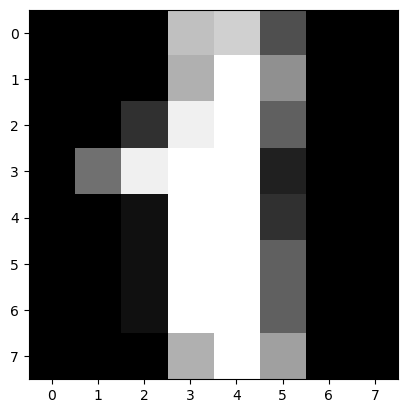

In [51]:
plt.imshow(digitsRaw.images[1], cmap='gray')

In [46]:
from scipy.ndimage import rotate, shift

In [52]:
# Take the first image
image = digitsRaw.images[1]

In [53]:
# Create augmented versions
rotated_image = rotate(image, angle=15, reshape=False)
shifted_image = shift(image, shift=(1, 1))

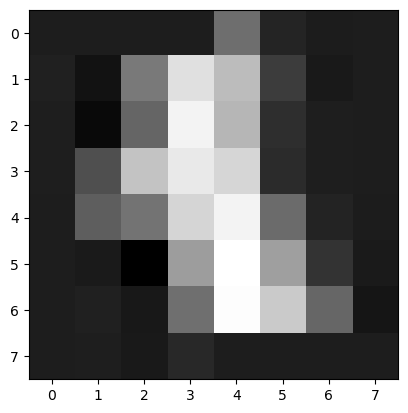

In [54]:
plt.imshow(rotated_image, cmap='gray')

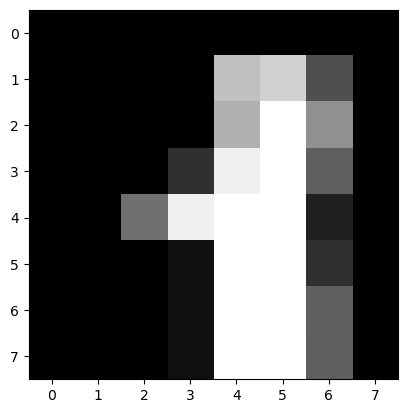

In [55]:
plt.imshow(shifted_image, cmap='gray')

In [56]:
from scipy.ndimage import zoom

zoomed = zoom(image, zoom=1.2)

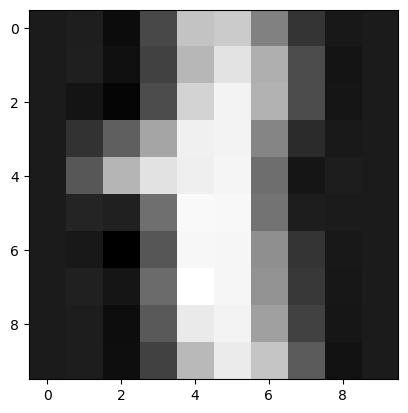

In [57]:
plt.imshow(zoomed, cmap='gray')